# 1. Imports and Parameters

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (mean_squared_error,mean_absolute_error,r2_score)

In [6]:
# Reproducibility
np.random.seed(42)
tf.keras.utils.set_random_seed(42)
# Lorenz parameters
sigma = 10.0
rho = 28.0
beta = 8.0 / 3.0
# Simulation parameters
dt = 0.01
T = 10000

# 2. Lorenz System

In [7]:
def lorenz(state):
    x, y, z = state
    dx = sigma * (y - x)
    dy = x * (rho - z) - y
    dz = x * y - beta * z
    return np.array([dx, dy, dz])
def rk4_step(state, dt):
    k1 = lorenz(state)
    k2 = lorenz(state + 0.5 * dt * k1)
    k3 = lorenz(state + 0.5 * dt * k2)
    k4 = lorenz(state + dt * k3)
    next_state = state + (dt / 6.0) * (
        k1 + 2*k2 + 2*k3 + k4
    )
    return next_state 

# 3. Data Generation

(30, 10001, 3)


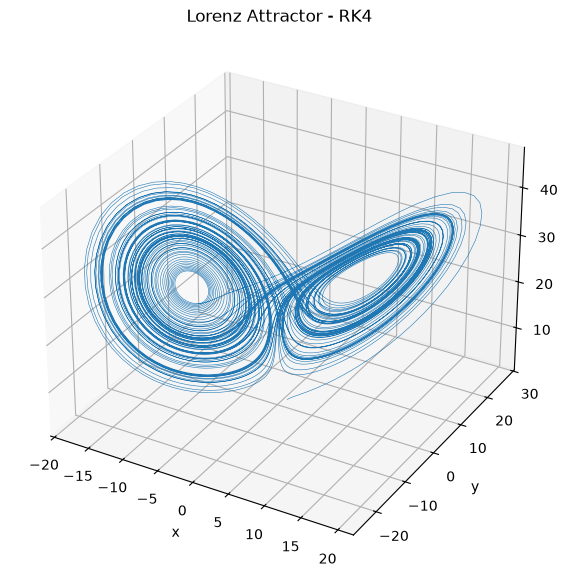

In [8]:
# Initial conditions
n_trajectories = 30
# Storage
trajectories = []

for i in range(n_trajectories):
    # Random initial conditions
    initial_state = np.random.uniform(0.5, 2.0, size=3)
    state = initial_state.copy()
    # New storage for each trajectory
    trajectory = np.zeros((T + 1, 3))
    trajectory[0] = state
       # RK4 integration
    for t in range(T):
        state = rk4_step(state, dt)
        trajectory[t+1] = state
    # Save trajectory
    trajectories.append(trajectory)  
trajectories = np.array(trajectories)
print(trajectories.shape) 
trajectorie = trajectories[20]
x = trajectorie [:,0]
y = trajectorie [:,1]
z = trajectorie [:,2]

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot(x, y, z, linewidth=0.4)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.set_title("Lorenz Attractor - RK4")

plt.show()

# 4. Dataset Preparation

In [9]:
def make_derivative_dataset(data):

    X = data.reshape(-1, 3)

    x = X[:, 0]
    y = X[:, 1]
    z = X[:, 2]

    dx = sigma * (y - x)
    dy = x * (rho - z) - y
    dz = x * y - beta * z

    Y = np.column_stack([dx, dy, dz])

    return X, Y

In [10]:
train_data = trajectories[:20]
validation_data = trajectories[20:24]
test_data = trajectories[24:]

X_train_d, Y_train_d = make_derivative_dataset(train_data)

X_val_d, Y_val_d = make_derivative_dataset(validation_data)

X_test_d, Y_test_d = make_derivative_dataset(test_data)


print("Training:", X_train_d.shape, Y_train_d.shape)
print("Validation:", X_val_d.shape, Y_val_d.shape)
print("Test:", X_test_d.shape, Y_test_d.shape)

Training: (200020, 3) (200020, 3)
Validation: (40004, 3) (40004, 3)
Test: (60006, 3) (60006, 3)


# 5. Normalization

In [11]:
# Calculate normalization parameters from training data only

x_mean = X_train_d.mean(axis=0)
x_std = X_train_d.std(axis=0)

y_mean = Y_train_d.mean(axis=0)
y_std = Y_train_d.std(axis=0)

# Normalize inputs
X_train_dn = (X_train_d - x_mean) / x_std
X_val_dn = (X_val_d - x_mean) / x_std
X_test_dn = (X_test_d - x_mean) / x_std

# Normalize targets
Y_train_dn = (Y_train_d - y_mean) / y_std
Y_val_dn = (Y_val_d - y_mean) / y_std
Y_test_dn = (Y_test_d - y_mean) / y_std

print("Training:", X_train_dn.shape, Y_train_dn.shape)
print("Validation:", X_val_dn.shape, Y_val_dn.shape)
print("Test:", X_test_dn.shape, Y_test_dn.shape)    

Training: (200020, 3) (200020, 3)
Validation: (40004, 3) (40004, 3)
Test: (60006, 3) (60006, 3)


# 6. Neural Network

In [12]:
derivative_model = keras.Sequential([
    layers.Input(shape=(3,)),

    layers.Dense(128, activation='tanh'),
    layers.Dense(128, activation='tanh'),

    layers.Dense(3)
])


In [13]:
derivative_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

derivative_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │             512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 17,411 (68.01 KB)

 Trainable params: 17,411 (68.01 KB)

 Non-trainable params: 0 (0.00 B)

# 7. Model Training

In [14]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history_d = derivative_model.fit(
    X_train_dn,
    Y_train_dn,
    epochs=100,
    batch_size=256,
    validation_data=(X_val_dn, Y_val_dn),
    callbacks=[early_stop],
    verbose=0
)

# 8. Model Evaluation

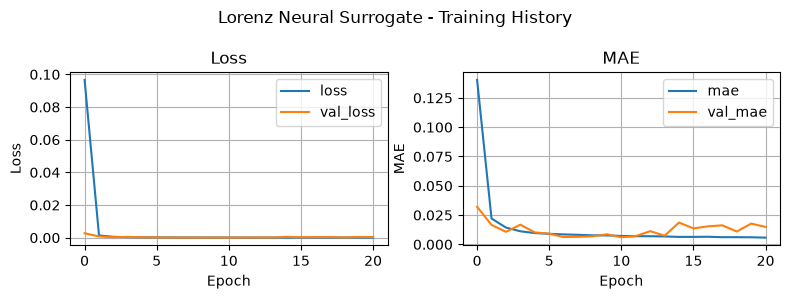

In [15]:
history_d.history.keys()
history_df= pd.DataFrame(history_d.history)

fig, ax = plt.subplots(1, 2, figsize=(8, 3))
# Loss plot
history_df[['loss', 'val_loss']].plot(
    ax=ax[0],
    grid=True
)
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")
ax[0].set_title("Loss")
# MAE plot
history_df[['mae', 'val_mae']].plot(
    ax=ax[1],
    grid=True
)
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("MAE")
ax[1].set_title("MAE")
fig.suptitle("Lorenz Neural Surrogate - Training History")
plt.tight_layout()
plt.savefig(
    "training_history.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [16]:
# Predict normalized derivatives
d_pred_norm = derivative_model.predict(X_test_dn, verbose=0)

# Convert predictions back to physical scale
d_pred = d_pred_norm * y_std + y_mean
mse_d = mean_squared_error(Y_test_d, d_pred)
mae_d = mean_absolute_error(Y_test_d, d_pred)
r2_d = r2_score(Y_test_d, d_pred)

print("Derivative prediction metrics:")
print("MSE:", mse_d)
print("MAE:", mae_d)
print("R2:", r2_d)

print("\nTrue derivative:")
print(Y_test_d[0])

print("\nPredicted derivative:")
print(d_pred[0])

Derivative prediction metrics:
MSE: 0.2529940109997958
MAE: 0.37175003805963036
R2: 0.9999380733630714

True derivative:
[12.14908967 11.71566965 -3.28489313]

Predicted derivative:
[11.94901516 16.64660715 -2.59698209]


# 9. Neural RK4

In [17]:
def learned_lorenz(state):

    state_norm = (state - x_mean) / x_std
    deriv_norm = derivative_model.predict(
        state_norm.reshape(1, 3),
        verbose=0
    )[0]
    deriv = deriv_norm * y_std + y_mean

    return deriv

def learned_rk4_step(state, dt):

    k1 = learned_lorenz(state)

    k2 = learned_lorenz(state + 0.5 * dt * k1)

    k3 = learned_lorenz(state + 0.5 * dt * k2)

    k4 = learned_lorenz(state + dt * k3)

    return state + (dt / 6.0) * (
        k1 + 2*k2 + 2*k3 + k4
    )

In [18]:
n_steps = 3000

initial_state = test_data[0, 0, :].copy()
predicted_trajectory = np.zeros((n_steps + 1, 3))
predicted_trajectory[0] = initial_state

for t in range(n_steps):

    predicted_trajectory[t+1] = learned_rk4_step(
        predicted_trajectory[t], dt
    )



true = test_data[0, :n_steps+1, :]

time = np.arange(n_steps+1) * dt 

# 10. Attractor Reconstruction

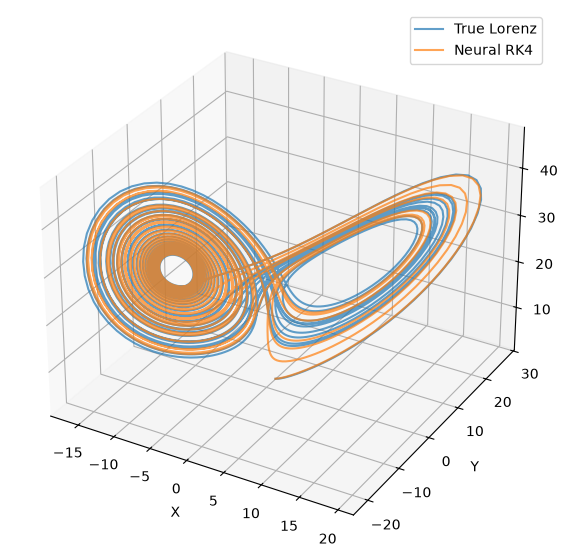

In [19]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot(
    true[:, 0], true[:, 1], true[:, 2],
    label='True Lorenz',
    alpha=0.7
)
ax.plot(
    predicted_trajectory[:, 0],
    predicted_trajectory[:, 1],
    predicted_trajectory[:, 2],
    label='Neural RK4',
    alpha=0.7
)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.legend()
plt.savefig(
    "trajectory.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 11. Probability Distributions

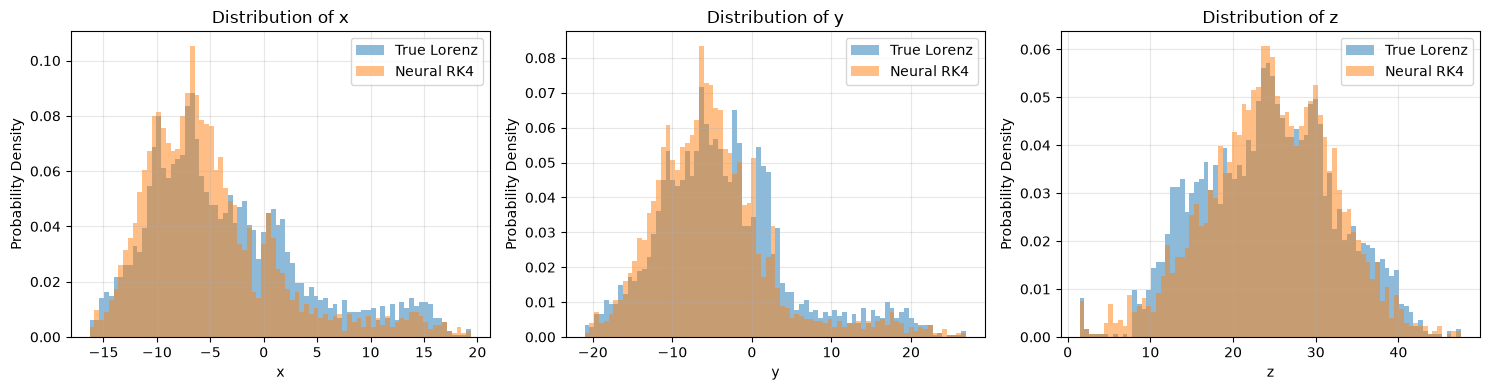

In [20]:
# Compare probability distributions

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

variables = ['x', 'y', 'z']

for i, var in enumerate(variables):

    # Common histogram bins for both datasets
    all_values = np.concatenate([
        true[:, i],
        predicted_trajectory[:, i]
    ])

    bins = np.linspace(
        all_values.min(),
        all_values.max(),
        81
    )

    # True Lorenz distribution
    axes[i].hist(
        true[:, i],
        bins=bins,
        density=True,
        alpha=0.5,
        label='True Lorenz'
    )

    # Neural RK4 distribution
    axes[i].hist(
        predicted_trajectory[:, i],
        bins=bins,
        density=True,
        alpha=0.5,
        label='Neural RK4'
    )

    axes[i].set_xlabel(var)
    axes[i].set_ylabel('Probability Density')
    axes[i].set_title(f'Distribution of {var}')
    axes[i].legend()
    axes[i].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    'lorenz_probability_distributions.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()



# 12. Autocorrelation

In [21]:
def autocorrelation(data, max_lag):

    data = data - np.mean(data)

    correlation = np.correlate(
        data, data, mode='full'
    )

    correlation = correlation[len(data)-1:]

    correlation = correlation / correlation[0]

    return correlation[:max_lag+1]

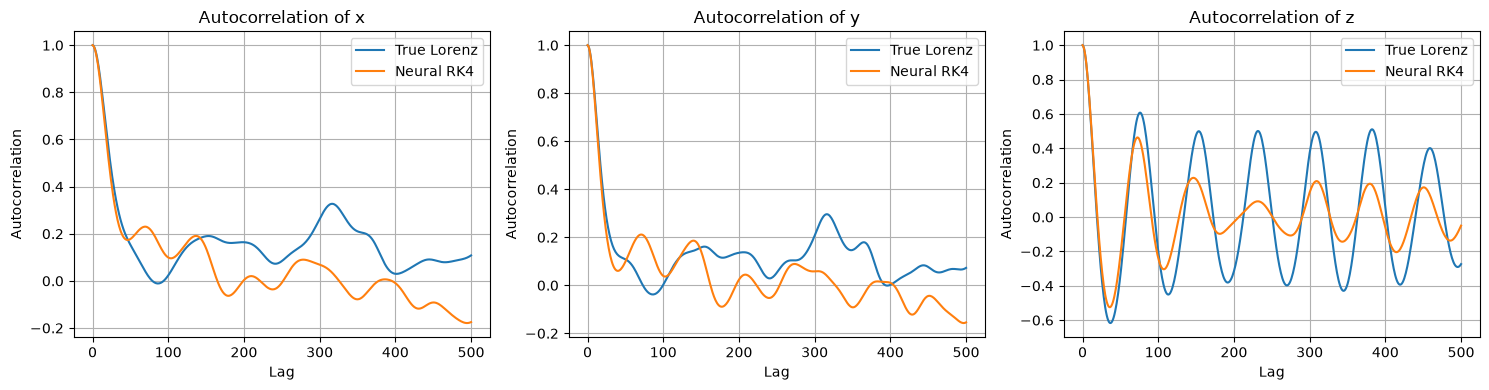

In [22]:
max_lag = 500
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
variables = ['x', 'y', 'z']
for i, var in enumerate(variables):
    ac_true = autocorrelation(true[:, i], max_lag)
    ac_pred = autocorrelation(predicted_trajectory[:, i], max_lag)

    axes[i].plot(ac_true, label='True Lorenz')

    axes[i].plot(ac_pred, label='Neural RK4')

    axes[i].set_xlabel('Lag')
    axes[i].set_ylabel('Autocorrelation')
    axes[i].set_title(f'Autocorrelation of {var}')
    axes[i].legend()
    axes[i].grid()
plt.tight_layout()
plt.show() 

# 13. Lyapunov Exponent

In [23]:
def true_field_batch(states):

    x = states[:, 0]
    y = states[:, 1]
    z = states[:, 2]

    dx = sigma * (y - x)
    dy = x * (rho - z) - y
    dz = x * y - beta * z

    return np.column_stack([dx, dy, dz])


def neural_field_batch(states):

    states_norm = (states - x_mean) / x_std

    deriv_norm = derivative_model(
        states_norm.astype(np.float32),
        training=False
    ).numpy()

    return deriv_norm * y_std + y_mean
def rk4_batch(states, dt, field):

    k1 = field(states)

    k2 = field(states + 0.5 * dt * k1)

    k3 = field(states + 0.5 * dt * k2)

    k4 = field(states + dt * k3)

    return states + (dt / 6.0) * (
        k1 + 2*k2 + 2*k3 + k4
    ) 
def estimate_largest_lyapunov(field,initial_state,dt,n_transient=1000,n_measure=5000,delta0=1e-4):
    rng = np.random.default_rng(42)
    direction = rng.normal(size=3)
    direction = direction / np.linalg.norm(direction)
    pair = np.vstack([
        initial_state,
        initial_state + delta0 * direction
    ])
    sum_log = 0.0
    count = 0
    total_steps = n_transient + n_measure
    for step in range(total_steps):
        pair_next = rk4_batch(pair, dt, field)
        if not np.all(np.isfinite(pair_next)):
            return np.nan
        difference = pair_next[1] - pair_next[0]
        distance = np.linalg.norm(difference)
        if not np.isfinite(distance) or distance < 1e-14:
            return np.nan
        if step >= n_transient:
            sum_log += np.log(distance / delta0)
            count += 1
        direction = difference / distance
        pair = np.vstack([
        pair_next[0],
        pair_next[0] + delta0 * direction])
    return sum_log / (count * dt)

In [24]:
lambda_true_list = []
lambda_neural_list = []

for j in range(len(test_data)):

    initial_state = test_data[j, 0, :].copy()

    lt = estimate_largest_lyapunov(
        true_field_batch,
        initial_state,
        dt,
        n_transient=1000,
        n_measure=5000
    )

    ln = estimate_largest_lyapunov(
        neural_field_batch,
        initial_state,
        dt,
        n_transient=1000,
        n_measure=5000
    )

    lambda_true_list.append(lt)
    lambda_neural_list.append(ln)

    print(f"\nTrajectory {j+1}")
    print(f"True:   {lt:.5f}")
    print(f"Neural: {ln:.5f}")    
print("\nFinal comparison")

print("True Lorenz:")
print("Mean:", np.mean(lambda_true_list))
print("Std:", np.std(lambda_true_list))

print("\nNeural Model:")
print("Mean:", np.mean(lambda_neural_list))
print("Std:", np.std(lambda_neural_list))    


Trajectory 1
True:   0.91734
Neural: 0.85612

Trajectory 2
True:   0.95205
Neural: 0.93233

Trajectory 3
True:   0.93223
Neural: 0.90862

Trajectory 4
True:   0.91023
Neural: 0.87200

Trajectory 5
True:   0.90652
Neural: 0.86631

Trajectory 6
True:   0.90129
Neural: 0.87960

Final comparison
True Lorenz:
Mean: 0.9199436958801432
Std: 0.017372330408353443

Neural Model:
Mean: 0.8858312754409842
Std: 0.026381601209265877


# 14. Phase-space Divergence

In [25]:
# Normalization parameters as TensorFlow constants
x_mean_tf = tf.constant(x_mean, dtype=tf.float32)
x_std_tf = tf.constant(x_std, dtype=tf.float32)

y_mean_tf = tf.constant(y_mean, dtype=tf.float32)
y_std_tf = tf.constant(y_std, dtype=tf.float32)

# Select test states
states_check = test_data[:, ::100, :].reshape(-1, 3)

states_tf = tf.convert_to_tensor(
    states_check,
    dtype=tf.float32
)


In [26]:
# Calculate Jacobian of the neural vector field
with tf.GradientTape() as tape:

    tape.watch(states_tf)

    states_norm = (states_tf - x_mean_tf) / x_std_tf

    derivatives_norm = derivative_model(
        states_norm,
        training=False
    )

    derivatives = derivatives_norm * y_std_tf + y_mean_tf

jacobian = tape.batch_jacobian(
    derivatives,
    states_tf
)

In [27]:
# Divergence = trace of Jacobian
neural_divergence = tf.linalg.trace(jacobian).numpy()

# True Lorenz divergence
true_divergence = -sigma - 1 - beta

print("True divergence:", true_divergence)

print("Neural divergence mean:",
      np.mean(neural_divergence))

print("Neural divergence std:",
      np.std(neural_divergence))

print("Mean absolute error:",
      np.mean(np.abs(neural_divergence - true_divergence)))    


True divergence: -13.666666666666666
Neural divergence mean: -12.763662
Neural divergence std: 1.3972354
Mean absolute error: 1.1248178


# 15. Full Lyapunov Spectrum

In [28]:
@tf.function
def true_step_jacobian(state):

    with tf.GradientTape() as tape:

        tape.watch(state)

        def f(s):
            x, y, z = s[0], s[1], s[2]

            return tf.stack([
                sigma * (y - x),
                x * (rho - z) - y,
                x * y - beta * z
            ])

        k1 = f(state)
        k2 = f(state + 0.5 * dt * k1)
        k3 = f(state + 0.5 * dt * k2)
        k4 = f(state + dt * k3)

        next_state = state + (dt / 6.0) * (
            k1 + 2*k2 + 2*k3 + k4
        )

    J = tape.jacobian(next_state, state)

    return next_state, J
   

@tf.function
def neural_step_jacobian(state):

    with tf.GradientTape() as tape:

        tape.watch(state)

        def f(s):

            s_norm = (s - x_mean_tf) / x_std_tf

            d_norm = derivative_model(
                tf.expand_dims(s_norm, axis=0),
                training=False
            )[0]

            return d_norm * y_std_tf + y_mean_tf

        k1 = f(state)
        k2 = f(state + 0.5 * dt * k1)
        k3 = f(state + 0.5 * dt * k2)
        k4 = f(state + dt * k3)

        next_state = state + (dt / 6.0) * (
            k1 + 2*k2 + 2*k3 + k4
        )

    J = tape.jacobian(next_state, state)

    return next_state, J    
def estimate_full_spectrum(
    step_function,
    initial_state,
    dt,
    n_transient=1000,
    n_measure=10000):

    state = tf.convert_to_tensor(
        initial_state,
        dtype=tf.float32
    )

    Q = np.eye(3)

    lyapunov_sums = np.zeros(3)

    total_steps = n_transient + n_measure

    for step in range(total_steps):

        next_state, J = step_function(state)

        J = J.numpy().astype(np.float64)

        # Evolution of perturbation directions
        M = J @ Q

        # QR decomposition
        Q, R = np.linalg.qr(M)

        # Accumulate logarithmic growth rates
        if step >= n_transient:

            lyapunov_sums += np.log(
                np.maximum(np.abs(np.diag(R)), 1e-300)
            )

        state = next_state

    exponents = lyapunov_sums / (n_measure * dt)

    return np.sort(exponents)[::-1]   


In [29]:
initial_state = test_data[0, 0, :].astype(np.float32)

spectrum_true = estimate_full_spectrum(
    true_step_jacobian,
    initial_state,
    dt
)

spectrum_neural = estimate_full_spectrum(
    neural_step_jacobian,
    initial_state,
    dt
)

print("True Lorenz spectrum:")
print(spectrum_true)

print("\nNeural model spectrum:")
print(spectrum_neural)

print("\nSum of true exponents:")
print(np.sum(spectrum_true))

print("\nSum of neural exponents:")
print(np.sum(spectrum_neural))    

True Lorenz spectrum:
[ 9.07373220e-01  2.06767899e-03 -1.45760010e+01]

Neural model spectrum:
[ 9.07976444e-01 -1.04008348e-02 -1.35697173e+01]

Sum of true exponents:
-13.66656012272311

Sum of neural exponents:
-12.67214172064425
